# E-02 — ablação de texto e metadados

E-02 testa somente `has_cta`, `title_tag_overlap` e `duration_bucket`. A comparação principal é com E-00 no rolling-origin; E-01 aparece apenas como referência do lote amplo que foi rejeitado.

In [1]:
from pathlib import Path
import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
EXPERIMENTS = ROOT / 'artifacts' / 'feature_experiments'
CONSUMPTION = pd.read_csv(ROOT / 'data' / 'gold' / 'pilot_consumption_table.csv')
plt.style.use('seaborn-v0_8-whitegrid')

## 1. Comparação entre E-00, E-01 e E-02

Menor MAE é melhor. A decisão usa rolling-origin, porque o teste final deve permanecer apenas como veredito posterior.

experiment,E00,E01,E02
model,,,
B0,0.7734,0.7734,0.7734
M1,0.7798,0.7861,0.7759
M2,0.7615,0.7972,0.7500
M3,0.7620,0.7894,0.7779


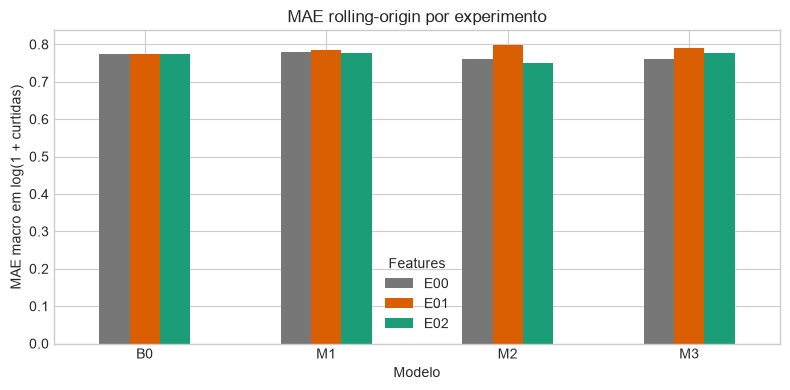

In [2]:
summaries = []
for experiment in ['e00', 'e01', 'e02']:
    summary = pd.read_csv(EXPERIMENTS / experiment / 'rolling_origin_summary.csv')
    summaries.append(summary.assign(experiment=experiment.upper()))
rolling_summary = pd.concat(summaries, ignore_index=True)
display(rolling_summary.pivot(index='model', columns='experiment', values='rolling_macro_mae_log_likes').round(4))

pivot = rolling_summary.pivot(index='model', columns='experiment', values='rolling_macro_mae_log_likes')
pivot.plot.bar(figsize=(8, 4), rot=0, color=['#777777', '#d95f02', '#1b9e77'])
plt.title('MAE rolling-origin por experimento')
plt.xlabel('Modelo')
plt.ylabel('MAE macro em log(1 + curtidas)')
plt.legend(title='Features')
plt.tight_layout()

## 2. E-02 realmente melhora M2?

A comparação é pareada por canal: calculamos o MAE médio de cada canal nos três cortes e depois a diferença `E-02 − E-00`. Valor negativo favorece E-02. Bootstrap e permutação evitam concluir apenas pelo valor médio.

In [3]:
def channel_error(experiment, model):
    metrics = pd.read_csv(EXPERIMENTS / experiment / 'rolling_origin_per_channel_metrics.csv')
    return (metrics.query('model == @model')
            .groupby('channel_name', as_index=False)['mae_log_likes'].mean()
            .rename(columns={'mae_log_likes': experiment}))

def paired_feature_comparison(model):
    paired = channel_error('e00', model).merge(channel_error('e02', model), on='channel_name')
    difference = (paired['e02'] - paired['e00']).to_numpy()
    rng = np.random.default_rng(42)
    bootstrap = rng.choice(difference, size=(10_000, len(difference)), replace=True).mean(axis=1)
    signs = np.array(list(itertools.product([-1, 1], repeat=len(difference))))
    permutation = (signs * difference).mean(axis=1)
    return paired.assign(delta_e02_menos_e00=difference), {
        'delta_mae_medio': difference.mean(),
        'ic_95': (np.quantile(bootstrap, .025), np.quantile(bootstrap, .975)),
        'p_valor_permutacao': (np.abs(permutation) >= abs(difference.mean())).mean(),
    }

m2_by_channel, m2_test = paired_feature_comparison('M2')
display(m2_by_channel.sort_values('delta_e02_menos_e00').round(4))
m2_test

,channel_name,e00,e02,delta_e02_menos_e00
9,NiinaSecrets,0.8326,0.7266,-0.1060
8,Mandy Candy,0.6698,0.6016,-0.0682
10,Steal The Look,0.7875,0.7606,-0.0269
6,Honda Automoveis,0.9988,0.9857,-0.0131
4,EstiloRenner,0.9181,0.9093,-0.0088
1,C&A Brasil,0.9649,0.9582,-0.0066
7,Hyundai Motor Brasil,0.6543,0.6555,0.0012
11,Volkswagen do Brasil,0.6257,0.6281,0.0024
0,Acelerados,0.7131,0.7261,0.0131
5,Hering Oficial,0.9724,0.9886,0.0162


{'delta_mae_medio': np.float64(-0.01148643973203041),
 'ic_95': (np.float64(-0.035074854911959406), np.float64(0.00822195093371744)),
 'p_valor_permutacao': np.float64(0.37841796875)}

,origin,macro_mae_log_likes_e00,macro_mae_log_likes_e02,delta
0,origin_1,0.7611,0.7323,-0.0289
1,origin_2,0.8077,0.7754,-0.0323
2,origin_3,0.7157,0.7424,0.0267


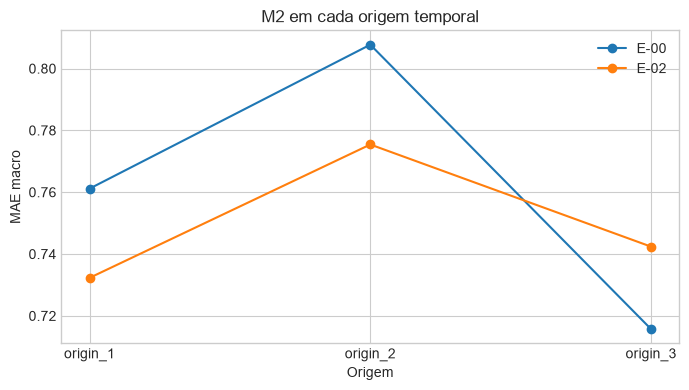

In [4]:
e00 = pd.read_csv(EXPERIMENTS / 'e00' / 'rolling_origin_by_cut.csv').query("model == 'M2'")
e02 = pd.read_csv(EXPERIMENTS / 'e02' / 'rolling_origin_by_cut.csv').query("model == 'M2'")
by_origin = e00[['origin', 'macro_mae_log_likes']].merge(e02[['origin', 'macro_mae_log_likes']], on='origin', suffixes=('_e00', '_e02'))
by_origin['delta'] = by_origin['macro_mae_log_likes_e02'] - by_origin['macro_mae_log_likes_e00']
display(by_origin.round(4))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(by_origin['origin'], by_origin['macro_mae_log_likes_e00'], marker='o', label='E-00')
ax.plot(by_origin['origin'], by_origin['macro_mae_log_likes_e02'], marker='o', label='E-02')
ax.set(title='M2 em cada origem temporal', xlabel='Origem', ylabel='MAE macro')
ax.legend()
plt.tight_layout()

## 3. Diagnóstico das três variáveis no M2 de E-02

O objetivo não é declarar causalidade; é verificar se os grupos têm tamanho suficiente e se concentram mais erro ou viés.

,has_cta,MAE,vies,n,variavel
0,0,0.7853,-0.0529,680,CTA
1,1,0.6062,0.0572,54,CTA


,duration_bucket,MAE,vies,n,variavel
0,01_15,0.6934,0.0910,130,Duração
1,16_30,0.7728,0.0776,164,Duração
2,31_60,0.8357,-0.0732,166,Duração
3,61_180,0.7704,-0.1654,274,Duração


,overlap_group,MAE,vies,n,variavel
0,0,0.7855,-0.0531,680,Título/tags
1,0–25%,0.5921,0.0371,53,Título/tags
2,>25%,1.2166,1.2166,1,Título/tags


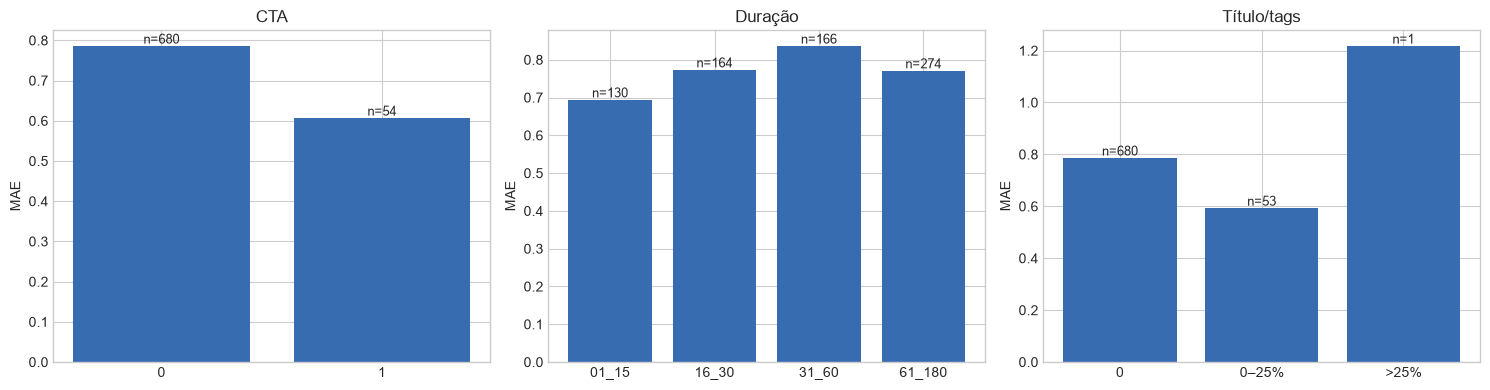

In [5]:
predictions = pd.read_csv(EXPERIMENTS / 'e02' / 'rolling_origin_predictions.csv').query("model == 'M2'")
diagnostic = predictions.merge(
    CONSUMPTION[['video_id', 'has_cta', 'title_tag_overlap', 'duration_bucket']],
    on='video_id', how='left'
)
diagnostic['absolute_error'] = (diagnostic['prediction_log_likes'] - diagnostic['target_log_likes']).abs()
diagnostic['residual'] = diagnostic['prediction_log_likes'] - diagnostic['target_log_likes']
diagnostic['overlap_group'] = pd.cut(diagnostic['title_tag_overlap'], [-.01, 0, .25, 1], labels=['0', '0–25%', '>25%'])

variables = [('has_cta', 'CTA'), ('duration_bucket', 'Duração'), ('overlap_group', 'Título/tags')]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (column, label) in zip(axes, variables):
    grouped = diagnostic.groupby(column, observed=False).agg(MAE=('absolute_error', 'mean'), vies=('residual', 'mean'), n=('video_id', 'size')).reset_index()
    display(grouped.assign(variavel=label).round(4))
    ax.bar(grouped[column].astype(str), grouped['MAE'], color='#386cb0')
    for index, row in grouped.reset_index(drop=True).iterrows():
        ax.text(index, row['MAE'], f"n={int(row['n'])}", ha='center', va='bottom', fontsize=9)
    ax.set(title=label, xlabel='', ylabel='MAE')
plt.tight_layout()

## Regra de decisão

Reter E-02 somente se a diferença E-02 − E-00 for negativa, estável entre origens e não piorar materialmente canais ou grupos. Caso o intervalo bootstrap inclua zero, o resultado permanece promissor, porém inconclusivo; a decisão então é repetir com mais canais ou mais cortes antes de usar no produto.